# Advanced Optimizers

Beyond SGD and Adam, `braintools.optim` provides the optimizers of optax with the same interface. They differ in how they turn the gradient into a step:

| Family | Optimizers | Idea |
|---|---|---|
| Adam variants | `Adam`, `AdamW`, `Adamax`, `Nadam`, `RAdam`, `AdaBelief`, `Yogi` | per-parameter steps from running gradient moments |
| Older adaptive | `Adagrad`, `RMSprop`, `Adadelta` | per-parameter steps from accumulated squared gradients |
| Sign-based | `Lion`, `Rprop` | step size independent of the gradient magnitude |
| Memory-efficient | `Adafactor`, `SM3` | compressed second-moment statistics |
| Layer-wise | `Lamb`, `Lars`, `Novograd`, `Fromage` | steps scaled per layer by the weight norm |
| Wrappers | `Lookahead` | averages "fast" weights of an inner optax optimizer |
| Quasi-Newton | `LBFGS` | curvature estimate from recent gradients, optionally with a line search |
| Second-order forward-mode | `SOFO`, `SOFOScan` | Gauss-Newton step in a random subspace, via forward-mode derivatives |

**Default learning rates differ widely**: 1e-3 for most Adam variants, 1e-4 for `Lion`, 1.0 for `Lars`, `SM3`, `Adadelta`, `Fromage`, and `LBFGS`. Always set `lr` for your problem.

## 1. Setup

In [1]:
import inspect

import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

import braintools
from braintools import optim

names = ["SGD", "Adam", "AdamW", "Adamax", "Nadam", "RAdam", "AdaBelief", "Yogi", "Adagrad", "RMSprop", "Adadelta",
         "Lion", "Rprop", "Adafactor", "SM3", "Lamb", "Lars", "Novograd", "Fromage", "LBFGS"]
print({n: inspect.signature(getattr(optim, n).__init__).parameters["lr"].default for n in names})

{'SGD': 0.001, 'Adam': 0.001, 'AdamW': 0.001, 'Adamax': 0.002, 'Nadam': 0.002, 'RAdam': 0.001, 'AdaBelief': 0.001, 'Yogi': 0.001, 'Adagrad': 0.01, 'RMSprop': 0.01, 'Adadelta': 1.0, 'Lion': 0.0001, 'Rprop': 0.01, 'Adafactor': None, 'SM3': 1.0, 'Lamb': 0.001, 'Lars': 1.0, 'Novograd': 0.001, 'Fromage': 1.0, 'LBFGS': 1.0}


## 2. A Fair Comparison

Comparing optimizers at one learning rate mostly compares how well that rate suits each of them. Below, every optimizer gets its best learning rate from a grid of five values, and runs for 300 full-batch steps on two problems:

- an **ill-conditioned quadratic** $\frac12 (x - c)^\top A (x - c)$ in 20 dimensions, eigenvalues from 1 to $10^3$, minimum at $c = (1, \dots, 1)$ (not at 0, so weight decay cannot help by accident);
- the **Rosenbrock** function, a curved valley.

The table shows the final loss for the best learning rate of each optimizer.

In [2]:
eigs = jnp.logspace(0, 3, 20)
Q = jnp.asarray(np.linalg.qr(np.random.default_rng(0).normal(size=(20, 20)))[0], jnp.float32)
A = Q @ jnp.diag(eigs) @ Q.T
problems = {
    "quadratic": (lambda x: 0.5 * (x - 1.0) @ A @ (x - 1.0), jnp.zeros(20)),
    "rosenbrock": (lambda x: (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2, jnp.array([-1.5, 2.0])),
}


def make(name, lr):
    if name == "SGD":
        return optim.SGD(lr=lr, momentum=0.9)
    return getattr(optim, name)(lr=lr)


def run(name, lr, f, x0, steps=300):
    x = brainstate.ParamState(x0)
    opt = make(name, lr)
    opt.register_trainable_weights({"x": x})

    @brainstate.transform.jit
    def step():
        grads = brainstate.transform.grad(lambda: f(x.value), grad_states={"x": x})()
        opt.update(grads)

    for _ in range(steps):
        step()
    value = float(f(x.value))
    return value if np.isfinite(value) else np.inf


lr_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
table = {}
for name in names[:-1]:  # LBFGS is treated separately below
    table[name] = {}
    for pname, (f, x0) in problems.items():
        losses = [run(name, lr, f, x0) for lr in lr_grid]
        best = int(np.argmin(losses))
        table[name][pname] = (losses[best], lr_grid[best])

print(f"{'optimizer':10s} {'quadratic':>20s} {'rosenbrock':>20s}")
for name, row in sorted(table.items(), key=lambda kv: kv[1]["quadratic"][0]):
    q, r = row["quadratic"], row["rosenbrock"]
    print(f"{name:10s} {q[0]:10.2e} (lr {q[1]:g}) {r[0]:10.2e} (lr {r[1]:g})")

optimizer             quadratic           rosenbrock
Adam         2.49e-09 (lr 1)   8.53e-03 (lr 1)
AdaBelief    3.09e-09 (lr 1)   7.37e-03 (lr 1)
Yogi         2.34e-08 (lr 1)   1.11e-02 (lr 1)
SGD          1.01e-04 (lr 0.001)   3.42e-02 (lr 0.001)
Novograd     1.56e-03 (lr 1)   1.75e-01 (lr 0.1)
Rprop        1.80e-02 (lr 0.001)   4.15e+00 (lr 0.001)
Adamax       3.94e-02 (lr 1)   8.81e-01 (lr 1)
AdamW        7.63e-02 (lr 1)   1.51e-01 (lr 1)
SM3          3.91e-01 (lr 1)   1.36e+00 (lr 1)
Adagrad      4.04e-01 (lr 1)   4.34e+00 (lr 1)
RMSprop      3.54e+00 (lr 0.01)   2.69e+00 (lr 0.1)
Fromage      4.71e+00 (lr 0.1)   2.35e-01 (lr 0.1)
Adafactor    4.93e+00 (lr 0.01)   1.97e-01 (lr 1)
Lamb         9.35e+00 (lr 0.1)   1.40e+00 (lr 0.01)
Nadam        1.33e+01 (lr 0.01)   2.55e-01 (lr 1)
Lion         1.64e+01 (lr 0.1)   2.25e-01 (lr 0.01)
Adadelta     4.19e+01 (lr 1)   5.08e+00 (lr 1)
RAdam        1.89e+02 (lr 0.001)   1.54e+00 (lr 0.01)
Lars         6.64e+02 (lr 0.0001)   1.51e+00 (lr 1)

No optimizer is best everywhere, and the ranking depends on the problem. Note also that the best learning rate spans orders of magnitude between optimizers: tuning `lr` per optimizer is not optional.

**RAdam** needs special care. Its variance rectification is inactive during the first few steps, which are then plain momentum SGD steps of size `lr * gradient`. With large gradients (Rosenbrock's gradient is about $10^3$ at the starting point) a learning rate that is fine for Adam makes it diverge immediately:

In [3]:
f, x0 = problems["rosenbrock"]
for lr in [0.05, 0.001]:
    print(f"RAdam lr={lr}: final loss {run('RAdam', lr, f, x0):.3g}   (Adam: {run('Adam', lr, f, x0):.3g})")

RAdam lr=0.05: final loss inf   (Adam: 1.71)


RAdam lr=0.001: final loss 5.88   (Adam: 5.91)


## 3. Quasi-Newton: `LBFGS`

L-BFGS builds a curvature model from recent gradients and is very effective on smooth, deterministic (full-batch) problems. Its line search needs the objective value and a **pure** function that evaluates the objective for given parameter values (a dict keyed like the registered weights):

In [4]:
for pname, (f, x0) in problems.items():
    x = brainstate.ParamState(x0)
    opt = optim.LBFGS(linesearch="zoom")
    opt.register_trainable_weights({"x": x})
    value_fn = lambda params: f(params["x"])  # pure: parameter values in, scalar out
    for _ in range(50):
        grads = brainstate.transform.grad(lambda: f(x.value), grad_states={"x": x})()
        opt.update(grads, value=f(x.value), value_fn=value_fn)
    print(f"{pname:10s}: L-BFGS with zoom line search, 50 steps -> loss {float(f(x.value)):.2e}")

quadratic : L-BFGS with zoom line search, 50 steps -> loss 4.81e-03


rosenbrock: L-BFGS with zoom line search, 50 steps -> loss 0.00e+00


On Rosenbrock, 50 L-BFGS steps reach the exact minimum, far better than 300 steps of any first-order method. On the ill-conditioned quadratic it converges steadily but, in float32, more slowly than the best adaptive methods; double precision (`jax_enable_x64`) helps line searches there. Its curvature model needs consistent gradients, so with noisy minibatch gradients prefer the first-order methods.

## 4. Optimizer Memory

Adaptive optimizers store extra statistics per parameter. For a single 1024 x 1024 weight matrix:

In [5]:
def state_size(opt):
    w = brainstate.ParamState(jnp.zeros((1024, 1024)))
    opt.register_trainable_weights({"w": w})
    leaves = jax.tree.leaves(opt.opt_state.value)
    return sum(int(np.prod(np.shape(leaf))) for leaf in leaves)


candidates = {
    "SGD": optim.SGD(lr=0.1),
    "SGD, momentum 0.9": optim.SGD(lr=0.1, momentum=0.9),
    "Adam": optim.Adam(lr=1e-3),
    "Lion": optim.Lion(lr=1e-4),
    "Adafactor": optim.Adafactor(lr=1e-3),
    "SM3 (default momentum=0.9)": optim.SM3(lr=0.1),
    "SM3, momentum=0": optim.SM3(lr=0.1, momentum=0.0),
}
for name, opt in candidates.items():
    print(f"{name:28s} optimizer state: {state_size(opt) / 1024 ** 2:7.4f} x the parameter count")

SGD                          optimizer state:  0.0000 x the parameter count
SGD, momentum 0.9            optimizer state:  1.0000 x the parameter count
Adam                         optimizer state:  2.0000 x the parameter count
Lion                         optimizer state:  1.0000 x the parameter count
Adafactor                    optimizer state:  0.0020 x the parameter count
SM3 (default momentum=0.9)   optimizer state:  1.0020 x the parameter count
SM3, momentum=0              optimizer state:  1.0020 x the parameter count


Adam keeps two full-size moment arrays and Lion one. Adafactor stores only row and column statistics for a matrix, about 0.2 % of the parameter count. SM3's second-moment statistics are just as small, but optax's implementation always allocates a full-size momentum buffer, even with `momentum=0`, so its state is still about one parameter's worth. When the optimizer state, not the model, limits memory, Adafactor is the option that actually saves it.

## 5. `Lookahead`

`Lookahead(base_optimizer, sync_period, alpha)` wraps an **optax** transformation: the inner optimizer takes `sync_period` fast steps, then the slow weights move a fraction `alpha` toward the fast ones. The averaging trades speed for stability: on a clean deterministic problem it only slows convergence, but with noisy gradients it reduces the noise the final weights carry. Here Gaussian noise is added to every gradient of a quadratic (median over 5 seeds):

In [6]:
A2 = Q @ jnp.diag(jnp.logspace(0, 2, 20)) @ Q.T
f2 = lambda x: 0.5 * (x - 1.0) @ A2 @ (x - 1.0)


def noisy_run(make_opt, seed, steps=500):
    x = brainstate.ParamState(jnp.zeros(20))
    opt = make_opt()
    opt.register_trainable_weights({"x": x})

    @brainstate.transform.jit
    def step(key):
        grads = brainstate.transform.grad(lambda: f2(x.value), grad_states={"x": x})()
        opt.update({"x": grads["x"] + 5.0 * jax.random.normal(key, (20,))})

    key = jax.random.PRNGKey(seed)
    for _ in range(steps):
        key, sub = jax.random.split(key)
        step(sub)
    return float(f2(x.value))


for lr in [0.03, 0.1]:
    for label, make_opt in [("Adam", lambda: optim.Adam(lr=lr)),
                            ("Lookahead(Adam, k=5, alpha=0.5)", lambda: optim.Lookahead(optax.adam(lr), sync_period=5, alpha=0.5))]:
        final = np.median([noisy_run(make_opt, s) for s in range(5)])
        print(f"lr {lr:<4} {label:32s} median final loss {final:.3f}")

lr 0.03 Adam                             median final loss 0.628


lr 0.03 Lookahead(Adam, k=5, alpha=0.5)  median final loss 0.384


lr 0.1  Adam                             median final loss 1.487


lr 0.1  Lookahead(Adam, k=5, alpha=0.5)  median final loss 0.858


## 6. `SOFO`: Second-Order Forward-Mode Optimization

`SOFO(model, loss_fn, ...)` computes its own update direction: it pushes `tangent_size` random directions through the model with forward-mode derivatives, builds the Gauss-Newton matrix in that random subspace, solves a damped linear system, and applies the result as an SGD-style step. Because it needs the model and data, it is called as `opt.step(inputs, targets)` (returning the loss) instead of `opt.update(grads)`. Here it fits a small regression network next to Adam:

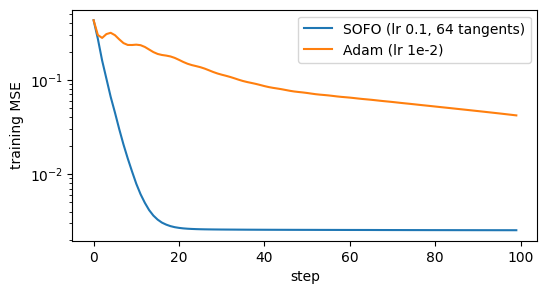

after 100 steps: SOFO 0.0025, Adam 0.0420 (noise floor 0.0025)


In [7]:
rng = np.random.default_rng(0)
X = jnp.asarray(rng.uniform(-2, 2, size=(256, 1)), jnp.float32)
Y = jnp.sin(2 * X) + 0.05 * jnp.asarray(rng.normal(size=(256, 1)), jnp.float32)


class Net(brainstate.nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = brainstate.nn.Linear(1, 32)
        self.l2 = brainstate.nn.Linear(32, 1)

    def __call__(self, x):
        return self.l2(jnp.tanh(self.l1(x)))


mse = lambda pred, target: jnp.mean((pred - target) ** 2)

brainstate.random.seed(0)
net = Net()
sofo = optim.SOFO(net, mse, lr=0.1, loss="mse", tangent_size=64)
sofo.register_trainable_weights(net.states(brainstate.ParamState))
sofo_curve = [float(sofo.step(X, Y)) for _ in range(100)]

brainstate.random.seed(0)
net_adam = Net()
params = net_adam.states(brainstate.ParamState)
adam = optim.Adam(lr=1e-2)
adam.register_trainable_weights(params)
adam_curve = []
for _ in range(100):
    grads, loss = brainstate.transform.grad(lambda: mse(net_adam(X), Y), grad_states=params, return_value=True)()
    adam.update(grads)
    adam_curve.append(float(loss))

fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(sofo_curve, label="SOFO (lr 0.1, 64 tangents)")
ax.semilogy(adam_curve, label="Adam (lr 1e-2)")
ax.set_xlabel("step")
ax.set_ylabel("training MSE")
ax.legend()
plt.show()
print(f"after 100 steps: SOFO {sofo_curve[-1]:.4f}, Adam {adam_curve[-1]:.4f} (noise floor 0.0025)")

On this small regression problem SOFO reaches the noise floor within about 20 steps, while Adam is still far from it after 100. Its learning rate still matters: at `lr=1.0` the same run diverges. `SOFOScan` is the recurrent variant: it takes an RNN cell and propagates the tangents through time with a scan.

## Summary

- Learning-rate defaults differ by orders of magnitude between optimizers; tune `lr` for each one before comparing.
- Rankings are problem-dependent; RAdam's first steps are plain momentum SGD, so it needs an SGD-sized `lr` when gradients are large.
- `LBFGS` excels on smooth full-batch problems; give it `value` and a pure `value_fn(params)` for its line search.
- `Adafactor` keeps optimizer state far smaller than Adam's (SM3, as implemented in optax, still allocates a full-size momentum buffer).
- `Lookahead` wraps an optax optimizer and helps mainly with noisy gradients; `SOFO` computes second-order steps with forward-mode derivatives and is driven by `step(inputs, targets)`.